In [115]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

import scipy.stats as stats

# Problem 1

In [116]:
X = np.array([1, 1.75, 2, 3, 3.25, 4])

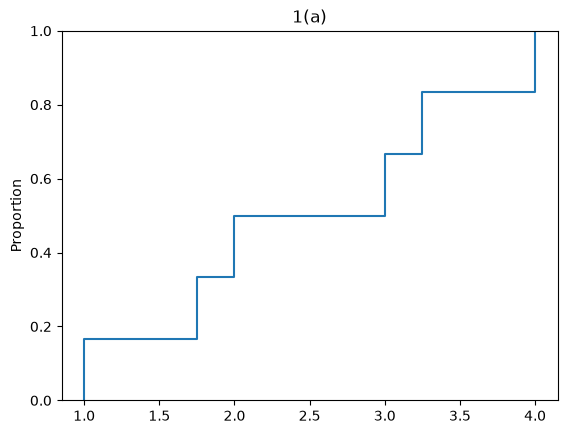

In [117]:
sns.ecdfplot(X)
plt.title('1(a)')
plt.show()

In [118]:
h = 0.2

In [119]:
uniform_kernel = lambda t: len(X[(t-h <= X) & (X <= t+h)])/(2*h*len(X))
gaussian_kernel = lambda t: np.exp(-((t-X)**2)/(2*h**2)).sum() / (np.sqrt(2*np.pi)*h*len(X))

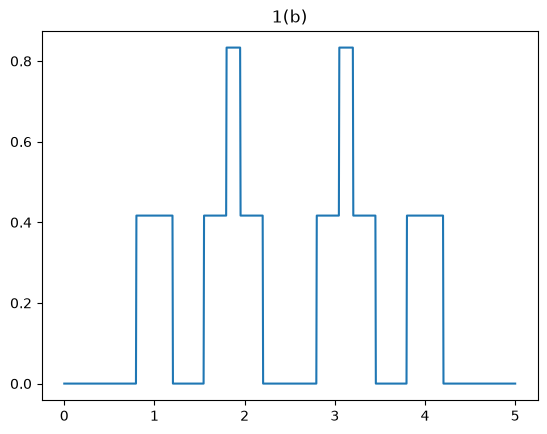

In [120]:
lin = np.linspace(0, 5, 1001)
plt.plot(lin, [uniform_kernel(x) for x in lin])
plt.title('1(b)')
plt.show()

In [121]:
# 1(c)

h = 1.84*X.std()*(len(X)**(-0.2))
print(f'h = {h:.3f}')

h = 1.299


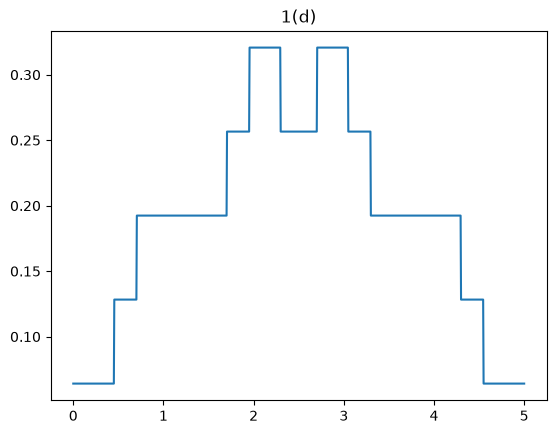

In [122]:
lin = np.linspace(0, 5, 1001)
plt.plot(lin, [uniform_kernel(x) for x in lin])
plt.title('1(d)')
plt.show()

`# 1(e)`

Both B and D highlight the same 2 peaks around 2 and 3. However, D makes a more normal distribution, while B has holes in between peaks. B is a better representation of where new data might land, and D is overfit to the current data.

# Problem 2

In [123]:
X = np.array([-1, -0.5, 0, 0.5, 1])

In [124]:
# 2(a)
h = 0.6

uniform_kernel(0)

0.5

In [125]:
# 2(b)
ecdf_proportion = lambda t: len(X[X <= t])/len(X)

E_f_hat = (ecdf_proportion(h) - ecdf_proportion(-h))/(2*h)
print(f'E[f_hat_h(0)] = {E_f_hat:.3f}')

E[f_hat_h(0)] = 0.500


In [126]:
# 2(c)
true_density = stats.Normal(mu=0, sigma=1).pdf(0)
print(f'True density = {true_density:.3f}')

True density = 0.399


`# 2(d)`

No, b and c are not equal. This suggests that density is a biased estimator, and the population variance is likely not equal to 1.

In [ ]:
# 2(e)
h = 0.1

E_f_hat = (ecdf_proportion(h) - ecdf_proportion(-h))/(2*h)
print(f'E[f_hat_h(0)] = {E_f_hat:.3f}')

E[f_hat_h(0)] = 10.000


As h decreases, the density at 0 only grows larger and larger, towards infinity. Therefore the gap between f and E(f_hat_h) is becoming larger as h shrinks.

`# 2(f)`

`f_hat_h` is not a consistent estimator, since it appears to diverge from the true population density.

`# 2(g)`

We want to choose a bandwidth value which is neither too large or too small. If `h` is too large, the KDE will flatten out and become uninteresting. If `h` is too small, the KDE will only peak around the existing data, and would not be adaptive to new data. We need a bandwidth that is somewhere in between, such as Silverman's h.

# Problem 3

In [128]:
X = np.array([5, 7, 7, 8, 10])
h = 1.5

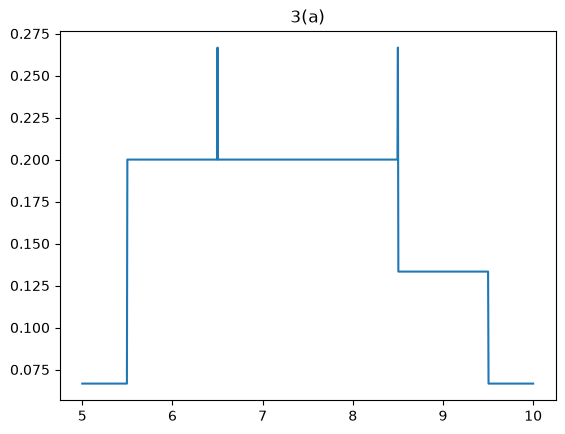

f_hat_h(6) = 0.200
f_hat_h(6.5) = 0.267
f_hat_h(7) = 0.200
f_hat_h(8) = 0.200
f_hat_h(8.5) = 0.267


In [129]:
lin = np.linspace(5, 10, 1001)
plt.plot(lin, [uniform_kernel(x) for x in lin])

plt.title('3(a)')
plt.show()

for x in [6, 6.5, 7, 8, 8.5]:
    print(f'f_hat_h({x}) = {uniform_kernel(x):.3f}')

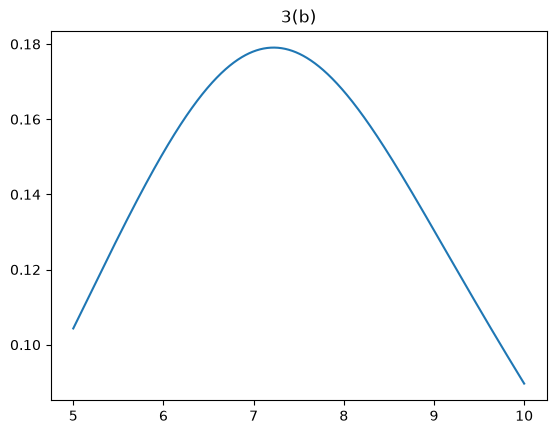

f_hat_h(6) = 0.151
f_hat_h(6.5) = 0.169
f_hat_h(7) = 0.178
f_hat_h(8) = 0.167
f_hat_h(8.5) = 0.151


In [130]:
lin = np.linspace(5, 10, 1001)
plt.plot(lin, [gaussian_kernel(x) for x in lin])

plt.title('3(b)')
plt.show()

for x in [6, 6.5, 7, 8, 8.5]:
    print(f'f_hat_h({x}) = {gaussian_kernel(x):.3f}')

`# 3(c)`

The a values jump at x=6.5 and x=8.5. These occur at the exact values where the window has points at both ends. For instance, x=6.5 is the only value which includes 5 and 8 in the window, and shifting it any amount will exclude one of those points from the window.

For the Gaussian kernel, its continuous nature allows curves to combine smoothly. The uniform kernel uses step functions with discontinuities, which allows for these sudden jumps. The smoothness of the Gaussian keeps it smooth when multiple are added together.

`# 3(d)`

The uniform kernel can be better for viewing discrete independent variables. Generally, the Gaussian kernel is better for continuous data, as it allows for smoother interpolation between data points.

# Problem 4

In [131]:
heart_data = pd.read_csv('./data/heart_failure_clinical_records_dataset.csv')
heart_data.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


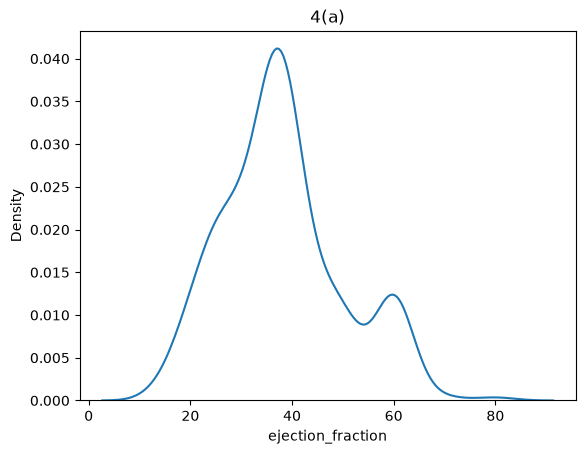

In [132]:
sns.kdeplot(heart_data, x='ejection_fraction')
plt.title('4(a)')
plt.show()

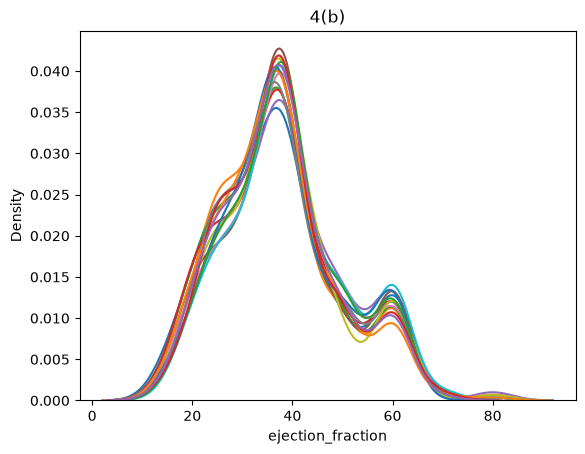

In [133]:
for _ in range(15):
    heart_sample = heart_data.sample(frac=1.0, replace=True)
    sns.kdeplot(heart_sample, x='ejection_fraction')

plt.title('4(b)')
plt.show()

`# 4(c)`

The most variation between the curves comes around the points in our original X array. The most consistent values occur in between these points.